In [71]:
import operator 
from langchain_community.tools.tavily_search import TavilySearchResults
from dotenv import load_dotenv
from typing import TypedDict, List, Annotated, Optional
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama
import os
from langchain_core.messages import SystemMessage, HumanMessage
from typing import Literal

In [72]:
load_dotenv()

True

In [73]:
class Task(BaseModel):
    id : int
    title : str
    brief : str = Field(..., description="What to cover")
    goal : str = Field(
        ..., 
        description = "One sentence describing what the reader should be able to do / understand after this section.",
    )

    bullets : List[str] = Field(
        ...,
        min_length = 3, 
        max_length = 5,
        description = "3-5 concrete, non - overlapping subpoints to cover in this section.",
    )

    target_words : int = Field(
        ...,
        description="target word count for this section (120 - 450)."
    )

    section_type : Literal[
        "Engaging Headlines","intro", "core", "example", "checklist", "common_mistakes","Links", "conclusion"
    ] = Field(
        ...,
        description="use 'common_mistakes' exactly once in the plan.",
    )

    tags : List[str] = Field(default_factory=list)
    requires_research : bool = False
    requires_citations : bool = False
    requires_code : bool = False



# plan 

class Plan(BaseModel):
    blog_title: str
    tasks : List[Task]
    audience : str = Field(..., description="Who is the person this blog is for.")
    tone : str = Field(..., description="Writing tone (e.g., practical, crisp, updated).")
    blog_kind : Literal["explainer","tutorial","news_roundup", "comparison", "system_design"] = "explainer"
    constraints : List[str] = Field(default_factory=list)



class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"] 
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence : List[EvidenceItem] = Field(default_factory=list)

In [74]:
class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None
    snippet: Optional[str] = None
    source: Optional[str] = None

In [75]:
load_dotenv()

True

In [76]:
class State(TypedDict):
    topic : str
    
    # routing / research
    mode : str
    needs_research : bool
    queries : List[str]
    evidence: List[EvidenceItem]
    plan : Optional[Plan]
    # reducer : results from workers get concatenated automatically
    sections : Annotated[List[tuple[int, str]], operator.add]
    final: str

In [77]:
llm = ChatOllama(
    model = "llama3.2:latest"
)

In [78]:
ROUTER_SYSTEM = """ You are a routing module for a technical blog planner.
Decide whether web research is needed Before planning.

Modes:
- Closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up to date examples/tools/models to be usefull.
- open_book (needs_research=true):
  mostly volatile : weekly roundups, "this week", "latest", ranking, pricing, policy/regulations.
  
  
if needs_research=true:
- Output 3-10 high- signal queries.
- Queries should be scoped and specific (avoid generic queries like "AI", or "LLM").
- if user asked for "last week/this week/latest", reflect that constraint In THE QUERIES.
"""

def router_node(state: State) -> dict:

    topic = state["topic"]
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic : {topic}",)
        ]
    )

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }



def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"

In [79]:
''' Research node or move toward tavily '''
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized : List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title":r.get("title") or "",
                "url":r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized

RESEARCH_SYSTEM = """ You are a research synthesizer for technical writing.

Given raw web search result , produce a deduplicates list of EvidenceItem objects.

Rules:
- Only include items within a non empty url.
- prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is expicitly present in the result payload , keep it as YYYY-MM_DD.
  if missing or unclear , set published_at=null. Do not guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:
    # take the first 10 queries from state 
    queries = (state.get("queries", []) or [])
    max_results = 6

    raw_results : List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence":[]}

    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results : \n{raw_results}"),
        ]
    )

    # deduplicate by url
    dedup = {}
    for e in pack.evidence:
        if e.url: 
            dedup[e.url] = e
    return {"evidence":list(dedup.values())}


In [80]:
def orchestrator(state: State) -> dict:
    planner = llm.with_structured_output(Plan)
    evidence = state.get("evidence",[])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(
                content=(
                    "You are a senior technical writer and developer advocate. Your job is to produce a "
                    "highly actionable outline for a technical blog post.\n\n"
                    "Hard requirements:\n"
                    "- Create 5–7 sections (tasks) that fit a technical blog.\n"
                    "- Each section must include:\n"
                    "  1) goal (1 sentence: what the reader can do/understand after the section)\n"
                    "  2) 3–5 bullets that are concrete, specific, and non-overlapping\n"
                    "  3) target word count (120–450)\n"
                    # "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
                    "Make it technical (not generic):\n"
                    "- Assume the reader is a developer; use correct terminology.\n"
                    "- Prefer design/engineering structure: problem → intuition → approach → implementation → "
                    "trade-offs → testing/observability → conclusion.\n"
                    "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X', "
                    "'Explain why Y fails under Z condition', 'Add a checklist for production readiness').\n"
                    "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
                    "  * a minimal working example (MWE) or code sketch\n"
                    "  * edge cases / failure modes\n"
                    "  * performance/cost considerations\n"
                    "  * security/privacy considerations (if relevant)\n"
                    "  * debugging tips / observability (logs, metrics, traces)\n"
                    "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what to build/compare/measure/verify.\n\n"
                    "Ordering guidance:\n"
                    "- Start with a crisp intro and problem framing.\n"
                    "- Build core concepts before advanced details.\n"
                    "- Include one section for common mistakes and how to avoid them.\n"
                    "- End with a practical summary/checklist and next steps.\n\n"
                    "Output must strictly match the Plan schema."
                )
            ),
            HumanMessage(
                content=(
                    f"Topic : {state['topic']}\n",
                    f"Mode: {mode}\n\n",
                    f"Evidence (only use for fresh claims; may be empty): \n",
                    f'{[e.model_dump() for e in evidence][:16]}'
                )
            ),
        ]
    )

    return {"plan": plan}

In [81]:
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task":task.model_dump(),
                "topic":state["topic"],
                "mode":state['mode'],
                "plan":state["plan"].model_dump(),
                "evidence":[e.model_dump() for e in state.get("evidence",[])],

            },

        )
        for task in state["plan"].tasks
    ]



In [82]:
def worker(payload: dict) -> dict:
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]
    evidence = [EvidenceItem(**e) if isinstance(e, dict) else e 
                for e in payload.get("evidence", [])]
    mode = payload.get("mode", "closed_book")
    # ✅ Re-hydrate ALL Pydantic models — LangGraph serializes them to dicts
    if isinstance(task, dict):
        task = Task.model_validate(task)
    if isinstance(plan, dict):
        plan = Plan.model_validate(plan)
    section_type = task.section_type
    bullets_text = "\n- " + "\n- ".join(task.bullets)
    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"-{e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )
    section_md = llm.invoke(
        [
                SystemMessage(content="""You are a senior technical writer and developer advocate.
                    Write ONE section of a technical blog post in Markdown.

                    Hard constraints:
                    - Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
                    - Stay close to Target words (±15%).
                    - Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
                    - Start with a '## <Section Title>' heading.

                    Scope guard (prevents mid-blog topic drift):
                    - If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
                    Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
                    Focus on summarizing events and implications.

                    Grounding policy:
                    - If mode == open_book (weekly news):
                    - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
                    - For each event claim, attach a source as a Markdown link: ([Source](URL)).
                    - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
                    - If requires_citations == true (hybrid sections):
                    - For outside-world claims, cite Evidence URLs the same way.
                    - Evergreen reasoning (concepts, intuition) is OK without citations unless requires_citations is true.

                    Code:
                    - If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

                    Style:
                    - Short paragraphs, bullets where helpful, code fences for code.
                    - Avoid fluff/marketing. Be precise and implementation-oriented.
                """),
                
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n"
                    # f"As-of: {as_of} (recency_days={recency_days})\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                    

                )
            )
        ]
    ).content.strip()

    return {"sections":[(task.id, section_md)]}





In [83]:

from pathlib import Path
def reducer(state: State) -> dict:
    plan = state["plan"]
    if plan is None:
        raise ValueError("Reducer called without a plan.")

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"# {plan.blog_title}\n\n{body}\n"

    # filename = f"{plan.blog_title}"+".md"
    # Path(filename).write_text(final_md, encoding="utf-8")

    # return {"final": final_md}

    output_path = Path("C:/Users/hp/Desktop/Blog_ChatAI/outputs").parent / f"{plan.blog_title}.md"
    Path(output_path).write_text(final_md, encoding="utf-8")



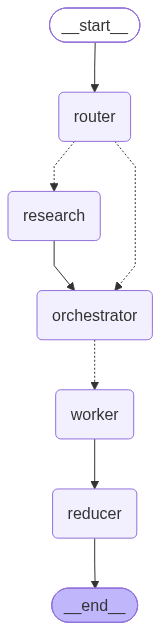

In [84]:
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node('orchestrator', orchestrator)
g.add_node('worker', worker)
g.add_node('reducer', reducer)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research":"research", "orchestrator":"orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app



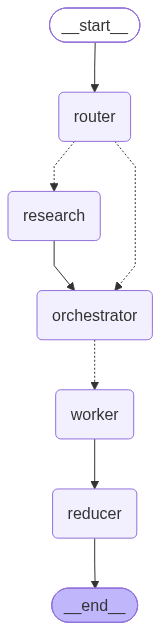

In [67]:
app

In [85]:
def run(topic: str):
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries":[],
            "evidence":[],
            "plan": None,
            "sections": [],
            "final": "",
        }
    )

    return out

In [86]:
run("write a blog on open Source LLMs in 2026")

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTP

{'topic': 'write a blog on open Source LLMs in 2026',
 'mode': 'open_book',
 'needs_research': True,
 'queries': [],
 'evidence': [],
 'plan': Plan(blog_title='Open Source LLMs in 2026: A Guide for Developers', tasks=[Task(id=1, title='Problem Framing', brief='Describe the current landscape of Open Source LLMs and the challenges developers face.', goal='Understand the current state of Open Source LLMs and the challenges developers face.', bullets=['Cite a recent paper or study highlighting the limitations of existing Open Source LLMs.', 'Explain how current Open Source LLMs differ from their commercial counterparts in terms of accuracy and performance.', 'Show a comparison chart or table highlighting the differences in training data, architecture, and hyperparameters among popular Open Source LLMs.', 'brief'], target_words=200, section_type='intro', tags=[], requires_research=False, requires_citations=False, requires_code=False), Task(id=2, title='Intuition and Background', brief='Prov

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
